# Visualization with Matplotlib

`DataFrame.plot()` is the fastest route from numbers to a chart — it wraps Matplotlib with convenient defaults.

This notebook uses a synthetic daily stock-price frame (generated in cell 1, so it runs offline and reproducibly) to explore line, bar, and pie charts plus plot styles.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
%matplotlib inline

np.random.seed(11)
rng = pd.date_range("2012-01-01", "2017-12-31", freq="D")
price = 80 + np.cumsum(np.random.normal(0, 0.8, len(rng)))
apple = pd.DataFrame({
    "Open": price, "High": price + np.random.uniform(0.5, 1.5, len(rng)),
    "Low": price - np.random.uniform(0.5, 1.5, len(rng)),
    "Close": price + np.random.normal(0, 0.5, len(rng)),
    "Volume": np.random.randint(1_000_000, 8_000_000, len(rng)),
}, index=rng)

In [2]:
# Local execution already has the data files.
# On Colab (which opens just this notebook) we download them:
NEEDS_FILES = []


In [3]:
# Fetch data files for this notebook (Colab opens only the notebook itself;
# on Colab the files below are downloaded from the repo).NEEDS_FILES = []

In [4]:
apple.head()

,Open,High,Low,Close,Volume
2012-01-01,81.399564,82.349488,80.885211,81.724859,6233602
2012-01-02,81.170705,82.260077,80.490186,81.285342,5435325
2012-01-03,80.783053,81.352841,79.532437,80.174896,3609243
2012-01-04,78.660398,79.210928,77.521704,79.202023,2595290
2012-01-05,78.653771,79.373497,77.702293,78.817153,5043926


## Line plots

- `apple.plot()` — all numeric columns, each as its own line.
- `apple.plot(y="Volume")` — one column.
- `apple[["High", "Low"]].plot()` — selected columns.

A `DatetimeIndex` (like these dates) gives you free, meaningful x-axis labels.

<Axes: >

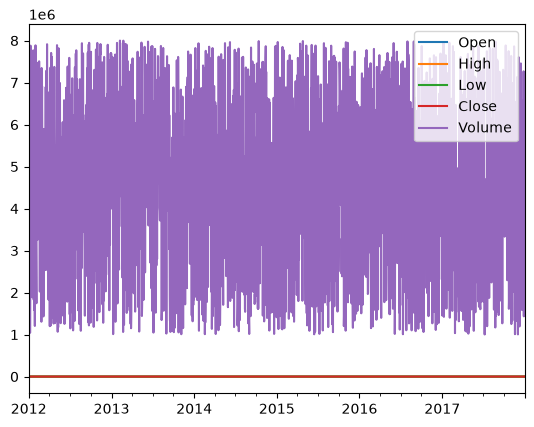

In [5]:
apple.plot()

<Axes: >

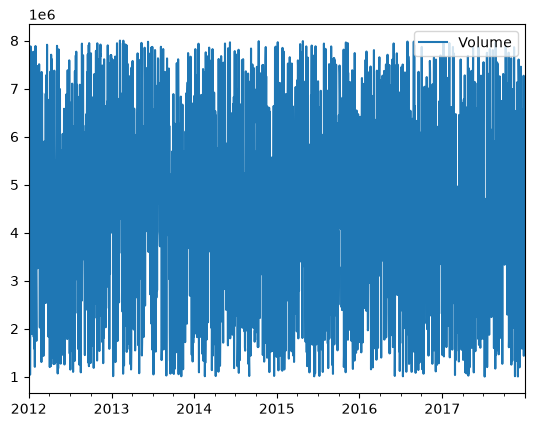

In [6]:
apple.plot(y="Volume")

<Axes: >

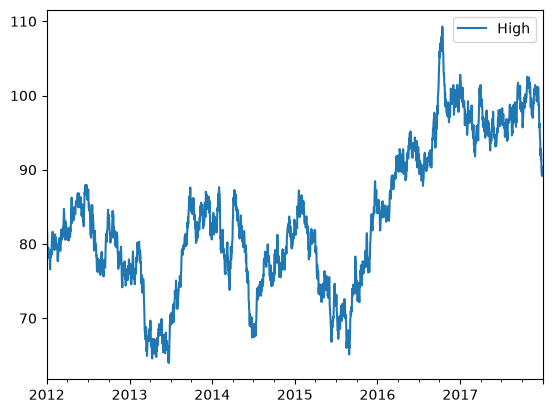

In [7]:
apple.plot(y="High")

<Axes: >

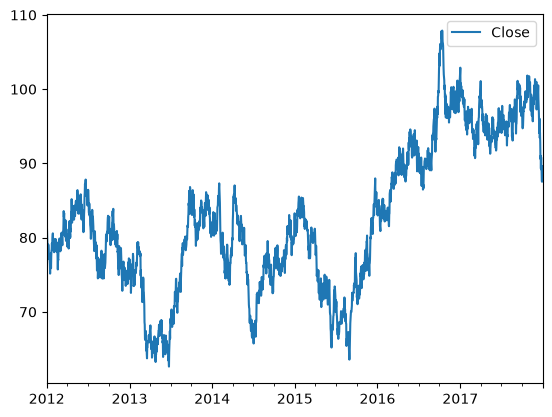

In [8]:
apple.plot(y="Close")

<Axes: >

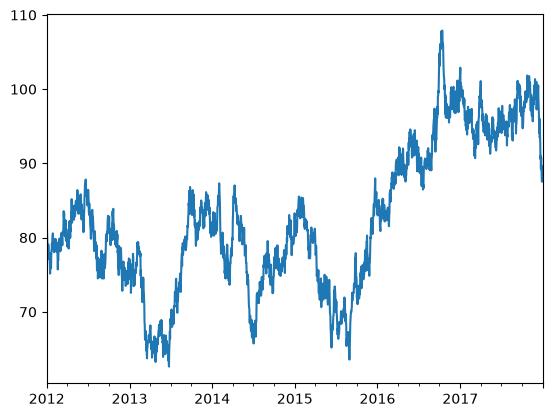

In [9]:
apple["Close"].plot()

<Axes: >

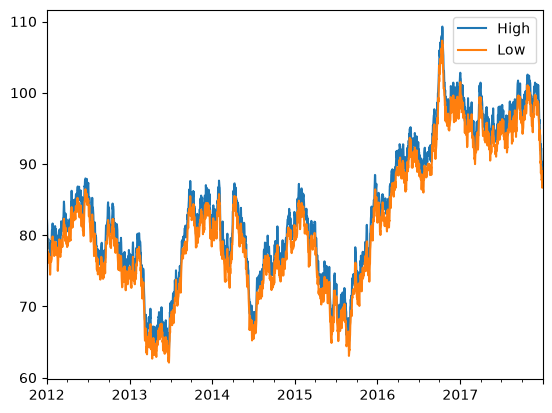

In [10]:
apple[["High","Low"]].plot()

## Plot styles

`plt.style.use(...)` swaps the entire look. `plt.style.available` lists all options. Style is presentation; it doesn't change the data.

In [11]:
plt.style.available

['Solarize_Light2',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'petroff6',
 'petroff8',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

<Axes: >

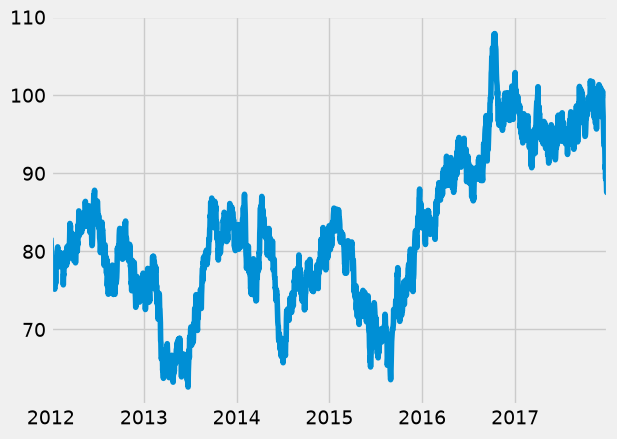

In [12]:
plt.style.use("fivethirtyeight")

apple["Close"].plot()

<Axes: >

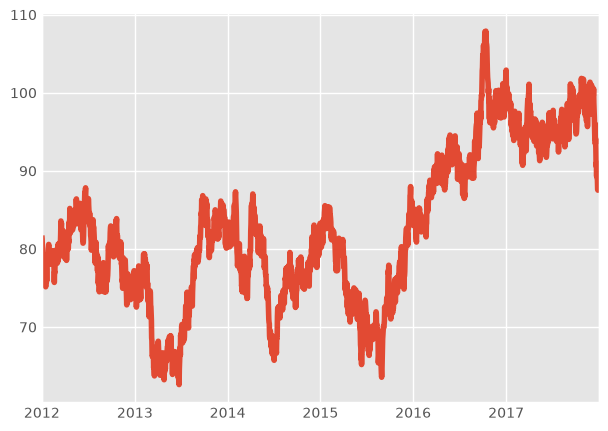

In [13]:
plt.style.use("ggplot")  # "seaborn-deep" was removed in Matplotlib 3.6+

apple["Close"].plot()

<Axes: >

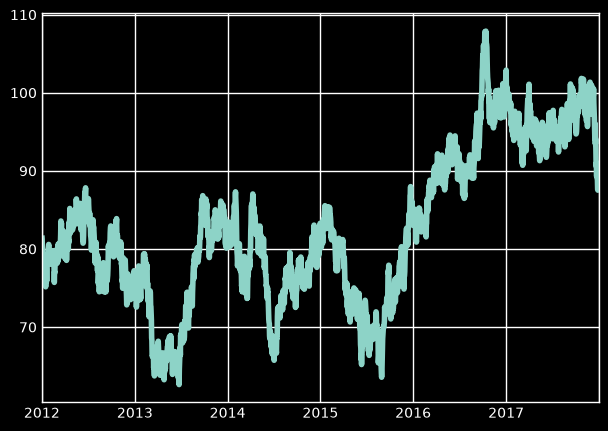

In [14]:
plt.style.use("dark_background")

apple["Close"].plot()

<Axes: >

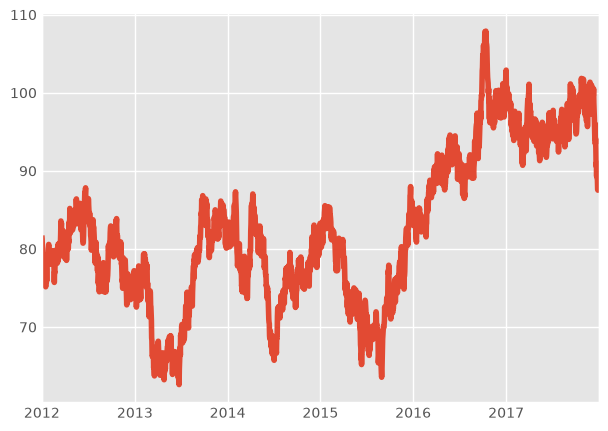

In [15]:
plt.style.use("ggplot")

apple["Close"].plot()

## From analysis to chart

`apple["Close"].apply(rank_performance)` maps prices to categories (Poor/Average/Awesome). `value_counts()` counts them, and `.plot(kind="bar")`, `"barh"`, or `"pie"` visualizes the distribution. This is the whole pattern of a categorical analysis.

In [16]:
def rank_performance(stock_price):
    if stock_price < 120:
        return "Poor"
    elif stock_price > 120 and stock_price < 150:
        return "Average"
    else:
        return "Awesome"
    

<Axes: xlabel='Close'>

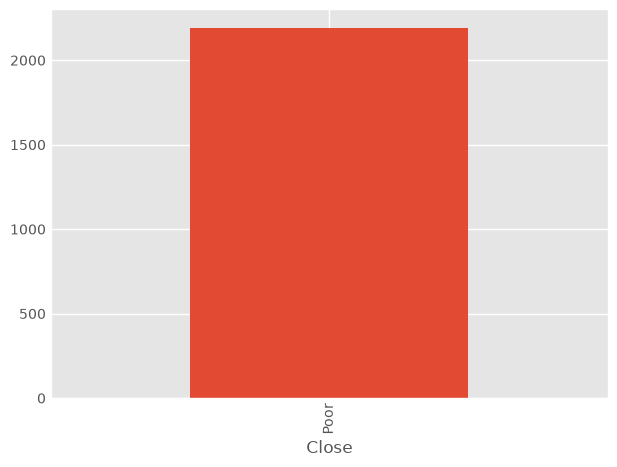

In [17]:
plt.style.use("ggplot")


apple["Close"].apply(rank_performance).value_counts().plot(kind="bar")

In [18]:
apple["Close"].min()

np.float64(62.63004372641575)

<Axes: ylabel='Close'>

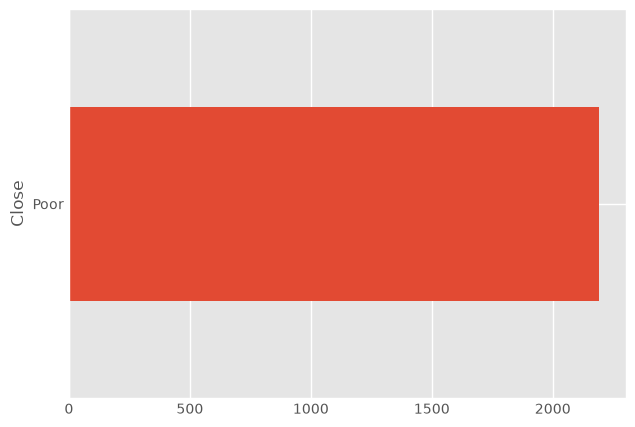

In [19]:
plt.style.use("ggplot")


apple["Close"].apply(rank_performance).value_counts().plot(kind="barh")

In [20]:
apple["Close"].mean()

np.float64(82.58038497567055)

<Axes: >

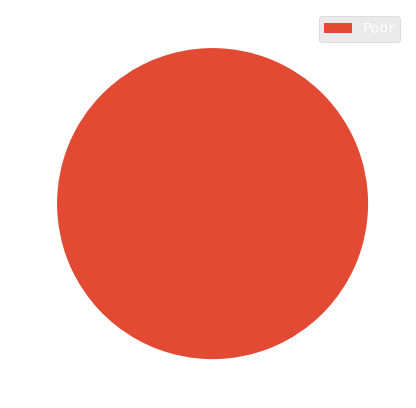

In [21]:
plt.style.use("ggplot")


apple["Close"].apply(rank_performance).value_counts().plot(kind="pie",legend=True)

## Binning with a function

`custom_round` buckets prices into rounded hundred-dollar bins; `value_counts().sort_index()` then shows the histogram-style distribution. For real histograms, `df["col"].hist()` is even simpler.

In [22]:
def custom_round(stock_price):
    return int(stock_price/100) * 100

In [23]:
apple['High'].apply(custom_round).value_counts().sort_index()

High
0      2078
100     114
Name: count, dtype: int64

In [24]:
apple["High"].min()

np.float64(64.0226794297118)

In [25]:
apple['Low'].apply(custom_round).nunique()

2